# 04 · The data pipeline again, in Spark with Delta Lake, for all three locales

**Goal:** rebuild the benchmark data layer of notebook 01 with PySpark and Delta Lake, on all three ESCI locales
(US, Spain, Japan), inside one Modal CPU container, and check every number against the pandas build. Then use the
same tables to look at Spark's execution model (plans, broadcast vs sort-merge joins, partition pruning) and at what
Delta Lake adds to a directory of Parquet files (MERGE, history, time travel, schema enforcement, RESTORE,
OPTIMIZE, VACUUM). Finally, score the saved rankings of notebooks 01 and 02 with window functions and compare to
`esci/metrics.py`.

| | |
|---|---|
| Data | the raw ESCI files already in the Modal Volume `esci-data`: 2.6M judgements (51 MB) and 1.8M products (1.1 GB), three locales |
| Engine | Apache Spark 4.2 in local mode (one JVM, one task slot per core) with Delta Lake 4.4, on an 8-core / 32 GB Modal container |
| Verification | `data/processed/us-small/stats.json` and `corpus.parquet` from notebook 01; the metrics in the saved `report.json` files |
| What is new | Delta Lake end to end; a pandas UDF as an oracle; the broadcast decision measured |
| Where it runs | Modal, CPU only. The laptop never starts a JVM; it launches the job and reads back a report of a few hundred KB |

Every cell was executed before this file was committed; Modal cells read saved reports when they exist.

**Is this big data?** No. 1.1 GB of Parquet fits in pandas on a laptop, and notebook 01 built the US benchmark in 23
seconds that way. Spark is used here for the same reason people learn it on a few million taxi trips: the API, the plans and the
Delta transaction log behave identically at 10 TB, and the best place to learn them is on data whose right
answers are already known.

## 1. What Delta Lake adds to Parquet

A Parquet "table" is a directory of immutable files. Four things go wrong the moment more than one process touches
it: a writer that dies half-way leaves a half-written table for every reader; a single row cannot be updated or
deleted without rewriting a file and nothing records which files are current; a job can append a file with a
different column type and the error surfaces later in someone else's job; an overwritten version is gone.

Delta Lake keeps a **transaction log** next to the files: `_delta_log/00000000000000000000.json`,
`…01.json`, one per commit, each listing the files added and removed and the schema. A reader starts from the
log, not from a directory listing, so it only ever sees complete commits. That one idea gives **ACID** writes
(Atomicity, Consistency, Isolation, Durability), `UPDATE` / `DELETE` / `MERGE`, schema enforcement, **time
travel** to any past version, `RESTORE`, and the maintenance commands `OPTIMIZE` (compact small files) and
`VACUUM` (delete files no live version references). Section 7 does each of these on a copy of the US judgements.

The layout is the usual **medallion** one: *bronze* = the raw files as shipped, *silver* = cleaned and joined
(the benchmark slice with passage text), *gold* = aggregates (per-query statistics). Each is a Delta table under
`esci-data/lake/<run>/`, partitioned by locale.

In [1]:
import json, time, textwrap
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from jobs import modal_spark

OUT, PROCESSED = Path("outputs"), Path("data/processed/us-small")
SMOKE, FULL = "spark-smoke", "spark-all"
STAGES = ["bronze", "silver", "gold", "plans", "delta", "score"]
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9.5})

def modal_once(run_name, launch, download=modal_spark.download_run):
    "Run a Modal job once: if its report is already in outputs/, read it back instead of paying for it again."
    p = OUT / run_name / "report.json"
    if p.exists():
        print(f"{run_name}: using the saved report at {p}")
        return json.loads(p.read_text())
    report = launch()
    download(run_name)
    return report

def frame(records, index=None):
    df = pd.DataFrame(records)
    return df.set_index(index) if index else df

print(f"Modal rate for {modal_spark.CPU} cores / {modal_spark.MEMORY_MB // 1024} GB: ${modal_spark.est_cost(3600):.3f} per hour at list price")

Modal rate for 8 cores / 32 GB: $0.632 per hour at list price


## 2. The container: Java, PySpark and the Delta JARs baked into the image

Spark is a Java program; `pyspark` is a thin client that starts a JVM and talks to it. Delta Lake's Python package
is thinner still: the actual code is a set of JARs that Spark normally fetches from Maven on the first session
start, into `~/.ivy2`. On a laptop that happens once and is cached; on Modal every container starts fresh, so the
image build starts a throwaway Delta session, lets Ivy resolve the JARs, and copies them into PySpark's own `jars/`
directory. After that no session needs `configure_spark_with_delta_pip`, the network, or Ivy. The build step is
one shell command (`modal_spark.BAKE_DELTA`):

In [2]:
print(textwrap.fill(modal_spark.BAKE_DELTA.replace(" && ", "\n&& "), 130, replace_whitespace=False))

python -c "from pyspark.sql import SparkSession; from delta import configure_spark_with_delta_pip as c; b =
SparkSession.builder.master('local[1]').config('spark.jars.ivy', '/root/.ivy2').config('spark.sql.extensions',
'io.delta.sql.DeltaSparkSessionExtension').config('spark.sql.catalog.spark_catalog',
'org.apache.spark.sql.delta.catalog.DeltaCatalog'); s = c(b).getOrCreate();
s.range(3).write.format('delta').mode('overwrite').save('/tmp/probe'); print('delta probe rows',
s.read.format('delta').load('/tmp/probe').count()); s.stop()"
&& cp /root/.ivy2/jars/io.delta_*.jar
/root/.ivy2/jars/io.unitycatalog_*.jar "$(python -c 'import pyspark, os; print(os.path.join(os.path.dirname(pyspark.__file__),
"jars"))')"/
&& rm -rf /tmp/probe /root/.ivy2
&& ls "$(python -c 'import pyspark, os;
print(os.path.join(os.path.dirname(pyspark.__file__), "jars"))')" | grep -i delta


**Local mode on 8 cores.** `master("local[*]")` runs the driver and all executors in one JVM with one task slot per
core, so every stage of every job splits into tasks that run 8 at a time. `spark.sql.shuffle.partitions` is
set to 32 instead of the default 200 (that default is for clusters; 200 tiny shuffle partitions on 8 cores means
scheduling overhead). The driver gets 20 GB of the 32 GB container; the pandas UDF in section 4 starts Python
worker processes that need the rest. Everything in `esci/spark.py` is a plain function that takes a `SparkSession`,
so it would run unchanged on a cluster or on Databricks.

## 3. Smoke run: US only, checked against the pandas build

The first paid run builds the lake for the US locale only and runs every stage. The point is verification: the
silver stage produces the same statistics dictionary that `esci.data.split_judgements` produced in notebook 01,
and the corpus stage produces passage text that must be byte-identical to `corpus.parquet`. One known difference:
the 500 dev queries are drawn with Spark's `rand(seed)` rather than numpy's `default_rng(seed)`, so *which*
training queries become dev differs; the train+dev totals and everything else must match exactly. (One count is
defined differently in the two builds and is reconciled in the cell: notebook 01 reported 338 training queries
dropped for losing their last Exact product, which leaves out 11 queries whose every judgement was removed; 349
is the full number, and 20,888 − 349 = 20,539 kept in both builds.)

In [3]:
with modal_spark.app.run():
    smoke = modal_once(SMOKE, lambda: modal_spark.spark_pipeline.remote(SMOKE, STAGES, ["us"], "small", 500, 42, modal_spark.DEFAULT_RANKINGS))
modal_spark.print_summary(smoke)

spark-smoke: using the saved report at outputs/spark-smoke/report.json
Spark 4.2.0, 8 task slots, stages: bronze 71s, silver 178s, gold 5s, plans 6s, delta 28s, score 13s
  us: 29,844 queries, 601,354 judgements, 482,105 products; train 20,039 q / dev 500 q / test 8,955 q; removed 66,945 overlapping judgements; leaked test products 0
  passage text vs pandas corpus: 482,105/482,105 identical
  bge-base, off the shelf            recall@10 0.3203  recall@20 0.4208  recall@50 0.5440  hit@20 0.7945  ndcg@20 0.3704
  bge-base fine-tuned (labelled)     recall@10 0.3561  recall@20 0.4610  recall@50 0.5851  hit@20 0.8101  ndcg@20 0.4109
  hybrid: BM25 + fine-tuned          recall@10 0.3531  recall@20 0.4635  recall@50 0.6000  hit@20 0.8248  ndcg@20 0.4096
container time 262s (all calls for this run) on 8 cores / 32 GB; estimated cost at list price $0.046


In [4]:
pandas_stats = json.loads((PROCESSED / "stats.json").read_text())
spark_stats = smoke["stages"]["silver"]["stats"]["us"]

rows = []
for k in ["queries_in_slice", "judgements_in_slice", "products_in_slice", "queries_dropped_no_exact", "train_queries_official",
          "train_judgements_official", "train_judgements_removed_product_overlap", "train_products_removed_product_overlap",
          "test_products_seen_in_final_train"]:
    rows.append((k, pandas_stats[k], spark_stats[k]))
# stats.json counts the training queries that lost their last Exact product but still had rows (338); the 11 queries whose
# every judgement was removed never reach that count. Spark counts official minus kept, so compare like with like:
rows.append(("train queries dropped after overlap removal (official - kept)",
             pandas_stats["train_queries_official"] - pandas_stats["train"]["queries"] - pandas_stats["dev"]["queries"],
             spark_stats["train_queries_dropped_after_overlap_removal"]))
for sub in ("test",):
    for k in ("queries", "judgements", "products", "exact_pairs"):
        rows.append((f"{sub}.{k}", pandas_stats[sub][k], spark_stats[sub][k]))
for k in ("queries", "judgements", "exact_pairs"):
    rows.append((f"train+dev.{k}", pandas_stats["train"][k] + pandas_stats["dev"][k], spark_stats["train"][k] + spark_stats["dev"][k]))
rows.append(("dev.queries", pandas_stats["dev"]["queries"], spark_stats["dev"]["queries"]))
cmp = pd.DataFrame(rows, columns=["statistic", "pandas (notebook 01)", "Spark"]).set_index("statistic")
cmp["match"] = np.where(cmp["pandas (notebook 01)"] == cmp["Spark"], "✓", "✗")
print(f"{(cmp['match'] == '✓').sum()} of {len(cmp)} statistics identical")
cmp

18 of 18 statistics identical


,pandas (notebook 01),Spark,match
statistic,,,
queries_in_slice,29844,29844,✓
judgements_in_slice,601354,601354,✓
products_in_slice,482105,482105,✓
queries_dropped_no_exact,1,1,✓
train_queries_official,20888,20888,✓
train_judgements_official,419653,419653,✓
train_judgements_removed_product_overlap,66945,66945,✓
train_products_removed_product_overlap,34750,34750,✓
test_products_seen_in_final_train,0,0,✓


In [5]:
v = smoke["stages"]["silver"]["verify_vs_pandas_corpus"]
print(f"passage text, Spark SQL vs pandas corpus.parquet: {v['identical']:,} of {v['products_compared']:,} products identical "
      f"({v['differ']} differ; {v['reference_rows']:,} rows in the reference) in {v['seconds']}s")
if v["examples"]:
    display(frame(v["examples"]))
c = smoke["stages"]["silver"]["corpus"]["us"]
print(f"corpus stats, Spark: {c['products']:,} products, mean {c['text_chars_mean']:.1f} chars, median {c['text_chars_median']:.0f}, "
      f"cut at 1,200: {c['share_cut_at_max_chars']:.3f}; pandas: {pandas_stats['corpus']['products']:,} products, "
      f"mean {pandas_stats['corpus']['text_chars_mean']}, median {pandas_stats['corpus']['text_chars_median']:.0f}, cut {pandas_stats['corpus']['share_cut_at_max_chars']}")

passage text, Spark SQL vs pandas corpus.parquet: 482,105 of 482,105 products identical (0 differ; 482,105 rows in the reference) in 13.6s
corpus stats, Spark: 482,105 products, mean 652.9 chars, median 617, cut at 1,200: 0.207; pandas: 482,105 products, mean 652.9, median 617, cut 0.207


## 4. Full run: all three locales

Same stages on `us`, `es` and `jp`. The lake for this run is the one the rest of the notebook reads.

In [6]:
with modal_spark.app.run():
    full = modal_once(FULL, lambda: modal_spark.spark_pipeline.remote(FULL, STAGES, ["us", "es", "jp"], "small", 500, 42, modal_spark.DEFAULT_RANKINGS))
modal_spark.print_summary(full)

spark-all: using the saved report at outputs/spark-all/report.json
Spark 4.2.0, 8 task slots, stages: bronze 96s, silver 200s, gold 6s, plans 7s, delta 27s, score 11s
  us: 29,844 queries, 601,354 judgements, 482,105 products; train 20,039 q / dev 500 q / test 8,955 q; removed 66,945 overlapping judgements; leaked test products 0
  es: 8,049 queries, 218,774 judgements, 167,761 products; train 4,999 q / dev 500 q / test 2,417 q; removed 29,362 overlapping judgements; leaked test products 0
  jp: 10,407 queries, 297,883 judgements, 233,850 products; train 6,679 q / dev 500 q / test 3,123 q; removed 36,556 overlapping judgements; leaked test products 0
  passage text vs pandas corpus: 482,105/482,105 identical
  bge-base, off the shelf            recall@10 0.3203  recall@20 0.4208  recall@50 0.5440  hit@20 0.7945  ndcg@20 0.3704
  bge-base fine-tuned (labelled)     recall@10 0.3561  recall@20 0.4610  recall@50 0.5851  hit@20 0.8101  ndcg@20 0.4109
  hybrid: BM25 + fine-tuned          rec

### Bronze: the raw files as Delta tables

`bronze_examples` and `bronze_products` are the two parquet files rewritten as Delta tables partitioned by
`product_locale`, nothing else changed. The "small" and "large" versions are flags on the same rows; the test
share is the official query split. Note the duplicate product rows in the products file, which notebook 01 removed
with `drop_duplicates` and the silver stage removes with `dropDuplicates`.

In [7]:
b = full["stages"]["bronze"]
display(frame(b["examples_per_locale"], "product_locale"))
display(frame(b["products_per_locale"], "product_locale").round({"title_chars_mean": 0, "share_with_bullets": 3, "share_with_description": 3}))
ls = frame(b["label_share_per_locale"], "product_locale")
display(ls.div(ls.sum(axis=1), axis=0).round(3))
print(f"files: {b['files']}; raw: {b['raw_mb']}; written in {b['examples_seconds']}s + {b['products_seconds']}s")

,judgements,queries,products,judgements_small,judgements_large,judgements_test
product_locale,,,,,,
es,356410,15180,259973,218774,356410,93347
jp,446053,18127,339059,297883,446053,118907
us,1818825,97345,1215851,601354,1818825,425762


,rows,distinct_product_ids,title_chars_mean,share_with_bullets,share_with_description
product_locale,,,,,
es,260011,260011,116.0,0.858,0.545
jp,339059,339059,62.0,0.739,0.441
us,1215854,1215854,106.0,0.853,0.531


,E,S,C,I
product_locale,,,,
es,0.567,0.250,0.058,0.126
jp,0.580,0.260,0.034,0.127
us,0.686,0.203,0.022,0.089


files: {'bronze_examples': {'parquet_files': 3, 'mb': 39.3}, 'bronze_products': {'parquet_files': 3, 'mb': 1101.6}}; raw: {'shopping_queries_dataset_examples.parquet': 51.3, 'shopping_queries_dataset_products.parquet': 1108.9}; written in 16.6s + 66.5s


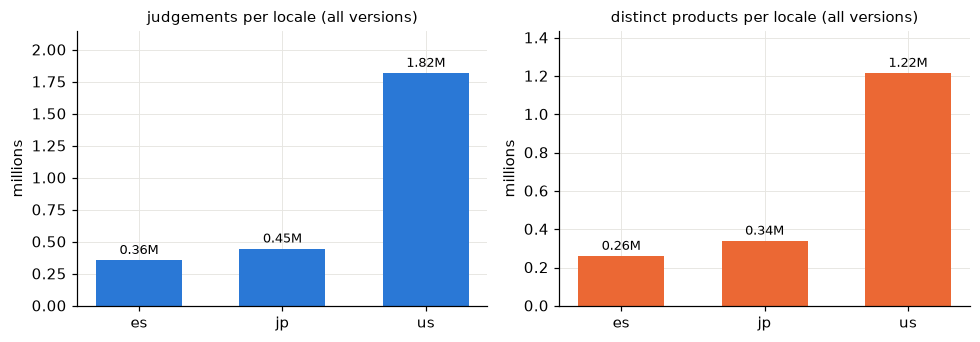

In [8]:
ex = frame(b["examples_per_locale"], "product_locale")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, col, color, title in ((axes[0], "judgements", BLUE, "judgements"), (axes[1], "products", ORANGE, "distinct products")):
    bars = ax.bar(ex.index, ex[col] / 1e6, color=color, width=0.6)
    ax.bar_label(bars, labels=[f"{v / 1e6:.2f}M" for v in ex[col]], padding=2, fontsize=8.5)
    ax.set_title(f"{title} per locale (all versions)", fontsize=10); ax.set_ylabel("millions"); ax.set_ylim(0, ex[col].max() / 1e6 * 1.18)
plt.tight_layout()

### Silver: the benchmark slice per locale

The split logic of notebook 01 as joins: a **semi join** keeps the queries that have at least one Exact product, an
**anti join** removes every training judgement whose product is in a test query's list (product-disjoint), a second
semi join drops training queries that lost their last Exact product, and a window function draws the dev queries.

In [9]:
s = full["stages"]["silver"]
rows = []
for loc, st in s["stats"].items():
    rows.append({"locale": loc, "queries": st["queries_in_slice"], "judgements": st["judgements_in_slice"], "products": st["products_in_slice"],
                 "no-Exact queries dropped": st["queries_dropped_no_exact"],
                 "train judgements removed (overlap)": st["train_judgements_removed_product_overlap"],
                 "removed share": st["train_judgements_removed_product_overlap"] / st["train_judgements_official"],
                 "train q": st["train"]["queries"], "dev q": st["dev"]["queries"], "test q": st["test"]["queries"],
                 "test Exact pairs": st["test"]["exact_pairs"], "test products leaked": st["test_products_seen_in_final_train"]})
display(pd.DataFrame(rows).set_index("locale").round({"removed share": 3}))
display(frame([{"locale": k, **v} for k, v in s["corpus"].items()], "locale").round(3))
print(f"duplicate (locale, product_id) keys in the products file: {s['products_file_duplicate_keys']:,}; "
      f"timings: {s['timings']}; files: {s['files']}")

,queries,judgements,products,no-Exact queries dropped,train judgements removed (overlap),removed share,train q,dev q,test q,test Exact pairs,test products leaked
locale,,,,,,,,,,,
us,29844,601354,482105,1,66945,0.160,20039,500,8955,79708,0
es,8049,218774,167761,0,29362,0.192,4999,500,2417,27074,0
jp,10407,297883,233850,0,36556,0.175,6679,500,3123,41597,0


,products,missing_from_products_file,text_chars_mean,text_chars_median,share_cut_at_max_chars,share_with_brand
locale,,,,,,
us,482105,0,652.893,617,0.207,0.944
jp,233850,0,286.549,187,0.002,0.828
es,167761,0,664.913,637,0.242,0.950


duplicate (locale, product_id) keys in the products file: 0; timings: {'judgements_write': 14.5, 'stats': 16.6, 'corpus_write': 53.7}; files: {'silver_judgements': {'parquet_files': 33, 'mb': 14.7}, 'silver_corpus': {'parquet_files': 48, 'mb': 476.5}}


### A pandas UDF as the second verification

The passage text is built twice: once in Spark SQL (`regexp_replace`, `concat_ws`, `substring`; runs in the JVM) and
once by calling the Python function `esci.data.product_text` from notebook 01 inside a **pandas UDF** (User Defined
Function): Spark ships each partition to a Python worker as Arrow batches, the function runs on a `pandas.Series`
per column, and the result comes back as a column. Python UDFs are the slow path (data crosses the JVM / Python
boundary) and the pandas flavour is the fast version of that slow path; the SQL expression needs no Python at all.
Here the UDF is the oracle: the share of identical texts per locale says whether the SQL translation is right,
including on Japanese full-width whitespace that `(?U)\s` has to match.

In [10]:
u = s["verify_sql_vs_pandas_udf"]
df = frame(u["per_locale"], "product_locale")
df["identical share"] = df["identical"] / df["products"]
display(df.round({"identical share": 5}))
print(f"pandas UDF pass over every product: {u['seconds']}s")
if u["examples"]:
    display(frame(u["examples"]))

,products,identical,identical share
product_locale,,,
es,167761,167761,1.0
jp,233850,233850,1.0
us,482105,482105,1.0


pandas UDF pass over every product: 43.1s


## 5. Gold: per-query statistics

One row per query kept in the benchmark (train + dev + test), from a single `groupBy` over the judgements with
conditional sums per label. `query_words` splits on whitespace, so it is meaningless for Japanese, where queries
have no spaces; the character count is the comparable number.

In [11]:
g = full["stages"]["gold"]
display(frame(g["per_locale"], "product_locale").T.round(2))
display(frame(g["per_locale_subset"]).pivot(index="product_locale", columns="subset", values=["queries", "exact_pairs"]))
display(frame(g["judged_histogram"], "product_locale"))
display(frame(g["most_judged"]))

product_locale,es,jp,us
queries,7916.00,10302.00,29494.00
judged_per_query_mean,23.79,25.26,18.02
judged_per_query_median,16.00,19.00,16.00
judged_per_query_max,65.00,96.00,134.00
exact_per_query_mean,10.18,12.01,8.03
exact_per_query_median,8.00,10.00,7.00
share_queries_all_exact,0.01,0.01,0.01
query_words_mean,3.46,1.82,3.88
query_chars_mean,21.45,10.58,22.93


queries              exact_pairs               
subset             dev  test  train         dev   test   train
product_locale                                                
es                 500  2417   4999        4831  27074   48680
jp                 500  3123   6679        5220  41597   76911
us                 500  8955  20039        3813  79708  153416

,<10,10-19,20-39,40+
product_locale,,,,
es,347,3941,2601,1027
jp,386,4819,2884,2213
us,1633,22567,3504,1790


,product_locale,query_id,query,n_judged,n_E,n_S,n_C,n_I
0,us,7534,airpods,134,42,50,36,6
1,us,83411,printer,120,67,0,29,24
2,jp,129080,脚立,96,41,0,25,30
3,us,58186,kindle,95,49,8,8,30
4,jp,97287,ssd,86,58,0,14,14
5,us,9690,apple earbuds,85,25,51,6,3
6,us,54460,iphone headphones,85,53,14,8,10
7,us,39158,face mask,83,62,5,1,15


## 6. Execution model: the plans behind two joins

`explain("formatted")` prints the physical plan Spark chose. Two joins carry the pipeline, and the plans below show
that the choice between the two join strategies is a **size estimate**, not a rule about which table is "big":

- **judgements ⋈ products**: 980k judgement rows against 1.8M product rows that carry the text. I expected a
  sort-merge join. Spark instead chose a `BroadcastHashJoin` with `BuildLeft`: the judgements side. After column
  pruning (three columns out of six) the Delta file statistics put it under the 10 MB
  `autoBroadcastJoinThreshold` (the whole table is 14.7 MB on disk), so Spark ships the small side to every task
  and streams the 1.1 GB products side through once, with no shuffle of it at all. The `Exchange` + `SortAggregate`
  under the products scan is the `dropDuplicates`, which is a shuffle of its own.
- **train anti-join test products**: the right side is a distinct set of (locale, product_id), small enough to
  broadcast too. Setting the threshold to -1 forces the alternative, a `SortMergeJoin`: both sides are shuffled by
  the key (`Exchange`), sorted, and merged. On this data the timing difference is small; it grows with the
  size of the big side, because the shuffle writes and reads every row. The point is to recognise the two shapes in a plan.

Also shown: a filter on the partition column appears as a `PartitionFilters` entry in the scan, so Spark reads one
locale's files and skips the rest (**partition pruning**), which is why the tables are partitioned by locale.

In [12]:
p = full["stages"]["plans"]
print(f"autoBroadcastJoinThreshold = {p['autoBroadcastJoinThreshold']} bytes; adaptive query execution = {p['adaptive_enabled']}\n")
print(f"[big join] {p['big_join_rows']:,} rows in {p['big_join_seconds']}s\n")
print(p["big_join_plan"][:3500])

autoBroadcastJoinThreshold = 10485760b bytes; adaptive query execution = true

[big join] 980,064 rows in 3.2s

== Physical Plan ==
AdaptiveSparkPlan (13)
+- Project (12)
   +- BroadcastHashJoin Inner BuildLeft (11)
      :- BroadcastExchange (3)
      :  +- Filter (2)
      :     +- Scan parquet  (1)
      +- SortAggregate (10)
         +- Sort (9)
            +- Exchange (8)
               +- SortAggregate (7)
                  +- Sort (6)
                     +- Filter (5)
                        +- Scan parquet  (4)


(1) Scan parquet 
Output [4]: [query_id#14135L, product_id#14136, esci_label#14138, product_locale#14134]
Batched: true
Location: PreparedDeltaFileIndex [file:/vol/data/lake/spark-all/silver_judgements]
PartitionFilters: [isnotnull(product_locale#14134)]
PushedFilters: [IsNotNull(product_id)]
ReadSchema: struct<query_id:bigint,product_id:string,esci_label:string>

(2) Filter
Input [4]: [query_id#14135L, product_id#14136, esci_label#14138, product_locale#14134]
Conditi

In [13]:
print(f"[anti join, broadcast] {p['anti_join_rows']:,} rows in {p['anti_join_seconds']}s\n")
print(p["anti_join_plan"][:2500])
print(f"\n[anti join, broadcast disabled -> sort-merge] {p['anti_join_no_broadcast_rows']:,} rows in {p['anti_join_no_broadcast_seconds']}s\n")
print(p["anti_join_no_broadcast_plan"][:2500])
print("\n[partition pruning: filter on product_locale = 'jp']\n")
print(p["partition_pruning_plan"])

[anti join, broadcast] 643,706 rows in 1.3s

== Physical Plan ==
AdaptiveSparkPlan (12)
+- Project (11)
   +- BroadcastHashJoin LeftAnti BuildRight (10)
      :- Filter (2)
      :  +- Scan parquet  (1)
      +- BroadcastExchange (9)
         +- HashAggregate (8)
            +- Exchange (7)
               +- HashAggregate (6)
                  +- Project (5)
                     +- Filter (4)
                        +- Scan parquet  (3)


(1) Scan parquet 
Output [6]: [query_id#14135L, product_id#14136, query#14137, esci_label#14138, subset#14139, product_locale#14134]
Batched: true
Location: PreparedDeltaFileIndex [file:/vol/data/lake/spark-all/silver_judgements]
PushedFilters: [IsNotNull(subset), Not(EqualTo(subset,test))]
ReadSchema: struct<query_id:bigint,product_id:string,query:string,esci_label:string,subset:string>

(2) Filter
Input [6]: [query_id#14135L, product_id#14136, query#14137, esci_label#14138, subset#14139, product_locale#14134]
Condition : (isnotnull(subset#14139) AND

## 7. Delta Lake operations on a copy of the US judgements

A re-judging batch arrives: 1,000 test pairs that were Substitute are re-labelled Exact, and 500 new judgements
for products not yet in the table are added. One `MERGE` applies both (update the matches, insert the rest) as
one atomic commit. Then: the frozen benchmark is still readable at version 0 (**time travel**); an append with the
wrong column type is refused (**schema enforcement**); `RESTORE` puts version 0 back as a new version, keeping the
history; `OPTIMIZE` compacts the files the MERGE produced and `VACUUM` deletes what no live version needs. The real
`silver_judgements` table is never touched: the demo works on `demo_judgements`.

In [14]:
d = full["stages"]["delta"]
print(f"version 0: {d['rows_v0']:,} rows, {d['exact_test_v0']:,} Exact test pairs")
print(f"after MERGE ({d['merge_seconds']}s): {d['rows_v1']:,} rows, {d['exact_test_v1']:,} Exact test pairs "
      f"(+{d['exact_test_v1'] - d['exact_test_v0']} relabelled, +{d['rows_v1'] - d['rows_v0']} inserted)")
print(f"versionAsOf 0 still reads {d['exact_test_versionAsOf_0']:,} Exact test pairs")
print(f"schema enforcement: {d['schema_enforcement']}")
print(f"after RESTORE to version 0: {d['exact_test_after_restore']:,} Exact test pairs; final row count {d['rows_final']:,}")
print(f"files: {d['files']}")
hist = frame(d["history"])
hist["operationMetrics"] = hist["operationMetrics"].map(lambda m: {k: v for k, v in m.items() if k in
    ("numOutputRows", "numTargetRowsUpdated", "numTargetRowsInserted", "numFiles", "numAddedFiles", "numRemovedFiles", "numRestoredFiles", "numRemovedFiles")})
display(hist)

version 0: 531,454 rows, 79,708 Exact test pairs
after MERGE (2.9s): 531,954 rows, 80,708 Exact test pairs (+1000 relabelled, +500 inserted)
versionAsOf 0 still reads 79,708 Exact test pairs
schema enforcement: refused (AnalysisException): [DELTA_FAILED_TO_MERGE_FIELDS] Failed to merge fields 'esci_label' and 'esci_label'
after RESTORE to version 0: 79,708 Exact test pairs; final row count 531,454
files: {'before_optimize': {'parquet_files': 14, 'mb': 11.3}, 'after_optimize': {'parquet_files': 15, 'mb': 17.9}, 'after_vacuum': {'parquet_files': 1, 'mb': 6.5}}


,version,operation,operationMetrics
0,0,WRITE,"{'numOutputRows': '531454', 'numRemovedFiles':..."
1,1,MERGE,"{'numOutputRows': '182186', 'numTargetRowsInse..."
2,2,RESTORE,"{'numRemovedFiles': '6', 'numRestoredFiles': '1'}"
3,3,OPTIMIZE,"{'numAddedFiles': '1', 'numRemovedFiles': '8'}"
4,4,VACUUM START,{}
5,5,VACUUM END,{}


## 8. Scoring the saved rankings in Spark

The rankings of notebooks 01 and 02 are parquet files with 100 ranked products per test query. recall@k, hit@k and
nDCG@k are a join to the judgements and a `groupBy` with conditional sums; the ideal DCG needs a window function
(`row_number` over each query's judgements ordered by gain). The numbers must equal the ones `esci.metrics.evaluate`
produced in Python, to the fourth decimal.

In [15]:
sc = full["stages"]["score"]
ref = {"bge-base, off the shelf": ("baselines-us-small", "BAAI/bge-base-en-v1.5"),
       "bge-base fine-tuned (labelled)": ("embed-v1-labelled", "after"),
       "hybrid: BM25 + fine-tuned": ("embed-v1-substitutes-hybrid", "hybrid(bm25+after)")}
rows = []
for label, r in sc["results"].items():
    run, key = ref[label]
    py = json.loads((OUT / run / "report.json").read_text())["results"][key]["metrics"]
    for m, v in r["metrics"].items():
        rows.append({"system": label, "metric": m, "Spark": v, "esci/metrics.py": py.get(m)})
cmp = pd.DataFrame(rows)
cmp["abs diff"] = (cmp["Spark"] - cmp["esci/metrics.py"]).abs()
print(f"{sc['test_queries']:,} test queries scored in {sc['seconds']}s; max |Spark - Python| = {cmp['abs diff'].max():.4f}")
cmp.pivot(index="metric", columns="system", values=["Spark", "esci/metrics.py"]).loc[["recall@10", "recall@20", "recall@50", "hit@20", "ndcg@20"]].round(4)

8,955 test queries scored in 11.3s; max |Spark - Python| = 0.0000


Spark                          \
system    bge-base fine-tuned (labelled) bge-base, off the shelf   
metric                                                             
recall@10                         0.3561                  0.3203   
recall@20                         0.4610                  0.4208   
recall@50                         0.5851                  0.5440   
hit@20                            0.8101                  0.7945   
ndcg@20                           0.4109                  0.3704   

                                                   esci/metrics.py  \
system    hybrid: BM25 + fine-tuned bge-base fine-tuned (labelled)   
metric                                                               
recall@10                    0.3531                         0.3561   
recall@20                    0.4635                         0.4610   
recall@50                    0.6000                         0.5851   
hit@20                       0.8248                         0.8101   
ndcg@20                      0.4096                         0.4109   

                                                             
system    bge-base, off the shelf hybrid: BM25 + fine-tuned  
metric                                                       
recall@10                  0.3203                    0.3531  
recall@20                  0.4208                    0.4635  
recall@50                  0.5440                    0.6000  
hit@20                     0.7945                    0.8248  
ndcg@20                    0.3704                    0.4096

## 9. Cost

In [16]:
rows = []
for name, rep in ((SMOKE, smoke), (FULL, full)):
    secs = rep["container_seconds"]
    rows.append({"run": name, "locales": ",".join(rep["locales"]), **{f"{k} s": v for k, v in rep["stage_seconds"].items()},
                 "container s": secs, "est. cost $": modal_spark.est_cost(secs)})
cost = pd.DataFrame(rows).set_index("run")
print(f"total estimated at list price: ${cost['est. cost $'].sum():.2f} (image build not included)")
cost

total estimated at list price: $0.11 (image build not included)


,locales,bronze s,silver s,gold s,plans s,delta s,score s,container s,est. cost $
run,,,,,,,,,
spark-smoke,us,71.1,178.1,5.2,5.9,28.2,13.2,261.5,0.046
spark-all,"us,es,jp",95.5,200.1,5.7,7.2,27.4,11.3,376.3,0.066


## 10. What comes next, and gotchas

- **Spark Connect.** The same functions, driven from a notebook on the laptop through a Spark Connect server in a
  Modal container (thin `pyspark-client` locally, no JVM). The container stays up while you work, so it costs
  more than a scripted run; what you gain is interactive `explain()` and `df.show()` on the real tables.
- **Databricks Free Edition**, to see the same Delta tables under Unity Catalog with Photon and serverless compute.
- **Delta JARs are not in the pip package.** Bake them into the image or every container start downloads them.
- **`spark.driver.memory` must be set before the JVM starts.** Through `SparkSession.builder.config` works in
  PySpark because the builder launches the JVM; setting it on a running session does nothing.
- **Python whitespace is not Java whitespace.** `str.split()` treats the ideographic space U+3000 as whitespace;
  Java's `\s` does not unless the pattern starts with `(?U)`. The pandas UDF check in section 4 is what caught it.
- **`rand(seed)` is reproducible but not numpy.** The dev subset differs from the pandas one; verify totals, not
  membership, or draw the subset once and store it (which is what `dev_corpus_ids.json` does for the training code).
- **200 shuffle partitions is a cluster default.** On 8 cores, 32 is plenty; the plans show the `Exchange` count,
  the stage count shows up in the timing.
- **VACUUM with 0 hours retention is a demo setting.** `retentionDurationCheck.enabled = false` is set only so the
  notebook can show the file count drop; production keeps the 7-day default so running readers never lose files.